# Ball-and-Rackets (Ball + Bingham) Nonlinear Fit

This notebook demonstrates a Ball-and-Rackets style model using a Bingham orientation distribution convolved with a stick response (the "racket"), plus an isotropic ball compartment.

Following common Ball-and-Rackets practice, the intrinsic diffusivity is shared between the racket response and the isotropic ball (`d_iso`).

In [ ]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing src/.")

repo_root = find_repo_root(Path.cwd().resolve())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import numpy as np
import matplotlib.pyplot as plt

from dmri_models import Component, LeastSquaresFitter, Model, Parameter, ParameterSpace, Simplex
from dmri_models.acquisitions import hcp
from dmri_models.compartments import Ball, BinghamFOD, FODConvolved, Stick

rng = np.random.default_rng(21)

In [ ]:
acquisition = hcp()
acquisition.print_summary()

----------------------------------------------------------------
Acquisition summary
- measurements: 170
- b-value shells (ms/um^2): 6 (tolerance: 0.100)
  - b=0.000: 10 measurements, 0 non-zero directions
  - b=0.500: 32 measurements, 32 non-zero directions
  - b=1.000: 32 measurements, 32 non-zero directions
  - b=2.000: 32 measurements, 32 non-zero directions
  - b=3.000: 32 measurements, 32 non-zero directions
  - b=6.000: 32 measurements, 32 non-zero directions
- gradient directions: 32 unique non-zero across 160 diffusion-weighted measurements
- b-tensor shape: 1.000
- pulse duration (ms): 24.000
- diffusion time (ms): 39.000
- gradient strength (T/m): 0.000 to 0.069
- echo time: n/a
- inversion time: n/a
- repetition time: n/a
----------------------------------------------------------------


In [10]:
fod = BinghamFOD(
    kappa1="kappa1",
    kappa2="kappa2",
    theta="theta",
    phi="phi",
    psi="psi",
    n_theta=20,
    n_phi=40,
)

racket = FODConvolved(
    response=Stick(diffusivity="d_iso", orientation="axis"),
    fod=fod,
    orientation_parameter="axis",
)

model = Model([
    Component("racket", racket),
    Component("ball", Ball(diffusivity="d_iso")),
])

parameter_space = ParameterSpace(
    [
        Parameter("S0", 1.0, (0.05, 2.0)),
        Parameter("d_iso", 2.0, (0.5, 3.5)),
        Parameter("kappa1", -8.0, (-128.0, 0.0)),
        Parameter("kappa2", -1.5, (-128.0, 0.0)),
        Parameter("theta", 1.1, (0.0, np.pi)),
        Parameter("phi", 0.8, (-np.pi, np.pi)),
        Parameter("psi", 0.2, (-np.pi, np.pi)),
    ],
    simplexes=[
        Simplex(("racket_fraction", "ball_fraction"), (0.75, 0.25)),
    ],
)

In [ ]:
true_parameters = parameter_space.initial_values()
true_parameters.update(
    {
        "S0": 1.0,
        "d_iso": 2.0,
        "kappa1": -10.0,
        "kappa2": -2.0,
        "theta": 0.9,
        "phi": 1.2,
        "psi": -0.3,
        "racket_fraction": 0.8,
        "ball_fraction": 0.2,
    }
)

SNR = 50
sigma = true_parameters["S0"] / SNR
signal_true = model.signal(acquisition, true_parameters)
signal_noisy = signal_true + rng.normal(0.0, sigma, size=signal_true.shape)

In [12]:
fitter = LeastSquaresFitter(model, parameter_space)
fit = fitter.fit(
    acquisition,
    signal_noisy,
    sigma=sigma,
    n_starts=20,
    max_nfev=3000,
    rng=rng,
)
fit.parameters

{'S0': 1.0022521487131968,
 'd_iso': 1.934823376256361,
 'kappa1': -12.211232965695983,
 'kappa2': -2.0679465270747217,
 'theta': 0.8933950081066478,
 'phi': 1.2046303097698752,
 'psi': -0.2947828398045228,
 'racket_fraction': 0.7783762303401339,
 'ball_fraction': 0.2216237696598661}

In [13]:
ordered_names = [
    "S0",
    "d_iso",
    "kappa1",
    "kappa2",
    "theta",
    "phi",
    "psi",
    "racket_fraction",
    "ball_fraction",
]

print(f"Success: {fit.success} | Cost: {fit.cost:.6f} | Evaluations: {fit.n_evaluations}")
print("\nParameter comparison (true vs fitted):")
for name in ordered_names:
    tv = true_parameters[name]
    fv = fit.parameters[name]
    err = fv - tv
    print(f"{name:16s} true={tv:8.4f}  fit={fv:8.4f}  error={err:+8.4f}")

Success: True | Cost: 70.001359 | Evaluations: 16

Parameter comparison (true vs fitted):
S0               true=  1.0000  fit=  1.0023  error= +0.0023
d_iso            true=  2.0000  fit=  1.9348  error= -0.0652
kappa1           true=-10.0000  fit=-12.2112  error= -2.2112
kappa2           true= -2.0000  fit= -2.0679  error= -0.0679
theta            true=  0.9000  fit=  0.8934  error= -0.0066
phi              true=  1.2000  fit=  1.2046  error= +0.0046
psi              true= -0.3000  fit= -0.2948  error= +0.0052
racket_fraction  true=  0.8000  fit=  0.7784  error= -0.0216
ball_fraction    true=  0.2000  fit=  0.2216  error= +0.0216


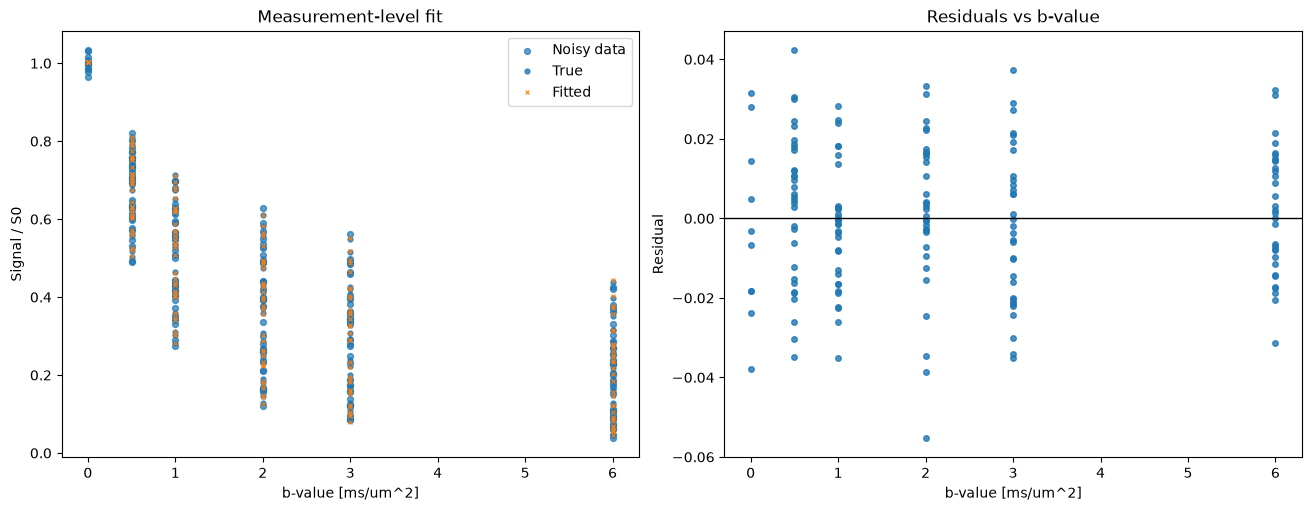

In [14]:
bvals = acquisition.b_values

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

axes[0].scatter(bvals, signal_noisy, s=18, alpha=0.7, label="Noisy data")
axes[0].plot(bvals, signal_true, "o", markersize=3.5, alpha=0.8, label="True")
axes[0].plot(bvals, fit.predicted_signal, "x", markersize=3.5, alpha=0.8, label="Fitted")
axes[0].set_xlabel("b-value [ms/um^2]")
axes[0].set_ylabel("Signal / S0")
axes[0].set_title("Measurement-level fit")
axes[0].legend()

residuals = signal_noisy - fit.predicted_signal
axes[1].scatter(bvals, residuals, s=16, alpha=0.8)
axes[1].axhline(0.0, color="k", linewidth=1)
axes[1].set_xlabel("b-value [ms/um^2]")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs b-value")

plt.show()